In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("Iris.csv")
X = df.drop(columns=["Id", "Species"], errors="ignore")
print(X.head())
print("Shape:", X.shape)

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2
Shape: (150, 4)


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (150, 4)


In [5]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
clusters = kmeans.fit_predict(X_scaled)
df["Cluster"] = clusters
print(df[["Species", "Cluster"]].head(10))
print("\nCluster counts:")
print(df["Cluster"].value_counts().sort_index())

       Species  Cluster
0  Iris-setosa        1
1  Iris-setosa        1
2  Iris-setosa        1
3  Iris-setosa        1
4  Iris-setosa        1
5  Iris-setosa        1
6  Iris-setosa        1
7  Iris-setosa        1
8  Iris-setosa        1
9  Iris-setosa        1

Cluster counts:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


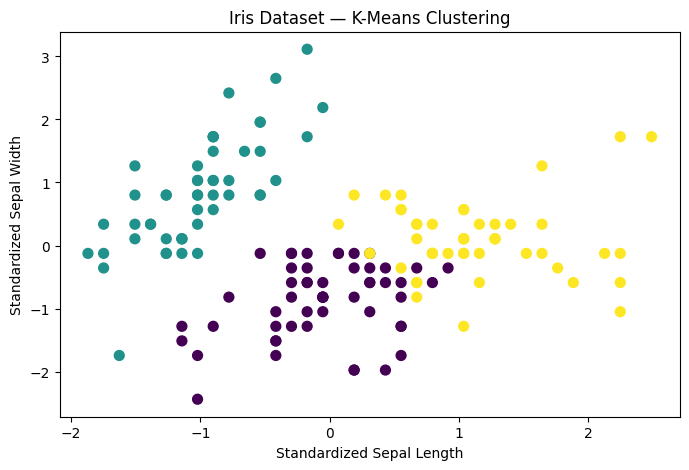

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    s=50
)
plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.title("Iris Dataset — K-Means Clustering")
plt.show()

In [7]:
score = silhouette_score(X_scaled, clusters)
print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.459


In [8]:
print(pd.crosstab(df["Species"], df["Cluster"]))

Cluster           0   1   2
Species                    
Iris-setosa       0  50   0
Iris-versicolor  39   0  11
Iris-virginica   14   0  36


In [10]:
import tensorflow_probability as tfp
tfd = tfp.distributions

In [11]:
initial_distribution = tfd.Categorical(
    probs=[0.8, 0.2]
)
transition_distribution = tfd.Categorical(
    probs=[
        [0.7, 0.3],  
        [0.2, 0.8]   
    ]
)
observation_distribution = tfd.Normal(
    loc=[0.0, 15.0],
    scale=[5.0, 10.0]
)

In [12]:
model = tfd.HiddenMarkovModel(
    initial_distribution=initial_distribution,
    transition_distribution=transition_distribution,
    observation_distribution=observation_distribution,
    num_steps=7
)

print("Expected temperatures over 7 days:")
print(model.mean().numpy())

Expected temperatures over 7 days:
[3.        5.9999995 7.4999995 8.25      8.625     8.812501  8.90625  ]


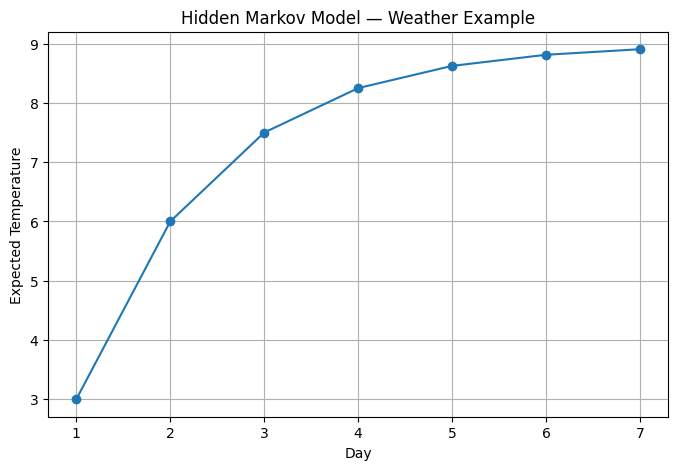

In [13]:
temperatures = model.mean().numpy()

days = range(1, len(temperatures) + 1)

plt.figure(figsize=(8, 5))
plt.plot(days, temperatures, marker="o")

plt.xlabel("Day")
plt.ylabel("Expected Temperature")
plt.title("Hidden Markov Model — Weather Example")
plt.xticks(list(days))
plt.grid(True)
plt.show()

In [14]:
for day, temp in zip(days, temperatures):
    print(f"Day {day}: Expected temperature = {temp:.2f}")
print("Initial state probabilities:")
print(initial_distribution.probs_parameter().numpy())

print("\nTransition probability matrix:")
print(transition_distribution.probs_parameter().numpy())

Day 1: Expected temperature = 3.00
Day 2: Expected temperature = 6.00
Day 3: Expected temperature = 7.50
Day 4: Expected temperature = 8.25
Day 5: Expected temperature = 8.62
Day 6: Expected temperature = 8.81
Day 7: Expected temperature = 8.91
Initial state probabilities:
[0.8 0.2]

Transition probability matrix:
[[0.7 0.3]
 [0.2 0.8]]
